# 🏥 CarePredict — 30-Day Hospital Readmission Prediction
### Machine Learning Project Work — Interactive Pipeline Notebook
* **Dataset:** HLT-005 Synthetic Hospital Admission Dataset (Hugging Face)
* **Objective:** Predict unplanned 30-day inpatient hospital readmission using clinical, demographic, and utilization features.
* **Target Variable:** `readmit_flag_30d` ($0$ = Not Readmitted within 30 days, $1$ = Readmitted within 30 days)
* **Class Imbalance:** 17.26% Readmission Incidence (82.74% Negative Class)
* **Algorithms Implemented:** Logistic Regression, Decision Tree, Random Forest
* **Evaluation Metrics:** Accuracy, Precision, Recall (Sensitivity), F1-Score, ROC-AUC, PR-AUC, Confusion Matrix

---
### Notebook Structure:
1. **Libraries & Environment Setup**
2. **Data Ingestion & Dataset Overview**
3. **Exploratory Data Analysis (EDA) & Inline Visualizations**
4. **Data Preprocessing & Zero-Leakage Patient-Level Split (`StratifiedGroupKFold`)**
5. **Feature Engineering & Clinical Diagnosis Mapping**
6. **Scikit-Learn Preprocessing Pipeline (`ColumnTransformer`)**
7. **Model Development & Training (3 Classifiers with Balanced Weights)**
8. **Comparative Evaluation & Performance Visualizations**
9. **Clinical Risk Inference Simulation (High-Risk vs. Low-Risk Patient)**
10. **Summary of Findings & Champion Model Selection**


## 1. Libraries & Environment Setup
We import standard data science and machine learning libraries. All seeds are fixed (`RANDOM_SEED = 42`) for strict reproducibility.


In [1]:
import os
import sys
import joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn tools
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "admissions.csv"
RESULTS_DIR = BASE_DIR / "results"
MODELS_DIR = BASE_DIR / "models"

print(f"✅ Setup Complete. Data path: {DATA_PATH}")


✅ Setup Complete. Data path: C:\Users\nisch\OneDrive\Documents\Hospital-Readmission-Prediction\data\admissions.csv


## 2. Data Ingestion & Dataset Overview
We load the **HLT-005 Synthetic Hospital Admission Dataset** (`data/admissions.csv`) and inspect its structural properties.


In [2]:
df_raw = pd.read_csv(DATA_PATH)

print(f"Total Hospital Encounters: {df_raw.shape[0]:,}")
print(f"Total Raw Features:        {df_raw.shape[1]}")
print(f"Unique Patients:           {df_raw['patient_id'].nunique():,}")
print(f"Average Visits per Patient: {len(df_raw)/df_raw['patient_id'].nunique():.2f}")

# Target distribution
target_counts = df_raw['readmit_flag_30d'].value_counts().sort_index()
print("\nTarget Class Counts:")
print(f"  • Not Readmitted (0): {target_counts[0]:,} ({target_counts[0]/len(df_raw)*100:.2f}%)")
print(f"  • Readmitted 30d (1): {target_counts[1]:,} ({target_counts[1]/len(df_raw)*100:.2f}%)")

df_raw[['admission_id', 'patient_id', 'age', 'los_days', 'cci_score', 'ms_drg_label', 'readmit_flag_30d']].head()


Total Hospital Encounters: 5,000
Total Raw Features:        76
Unique Patients:           1,580
Average Visits per Patient: 3.16

Target Class Counts:
  • Not Readmitted (0): 4,137 (82.74%)
  • Readmitted 30d (1): 863 (17.26%)


,admission_id,patient_id,age,los_days,cci_score,ms_drg_label,readmit_flag_30d
0,HLT005-ADM-00000001,HLT005-PAT-0000466,29,2.1,0,Perc Cardiovasc Proc w Drug Stent w/o MCC,0
1,HLT005-ADM-00000002,HLT005-PAT-0000258,54,7.5,1,Major Joint Replacement w MCC,0
2,HLT005-ADM-00000003,HLT005-PAT-0000791,0,1.4,2,Normal Newborn,1
3,HLT005-ADM-00000004,HLT005-PAT-0001530,78,5.2,1,Psychoses,0
4,HLT005-ADM-00000005,HLT005-PAT-0000251,65,10.3,9,Septicemia/Severe Sepsis w MCC,0


## 3. Exploratory Data Analysis (EDA)
Visualizing class distribution, age patterns, length of stay, and clinical predictor correlations.


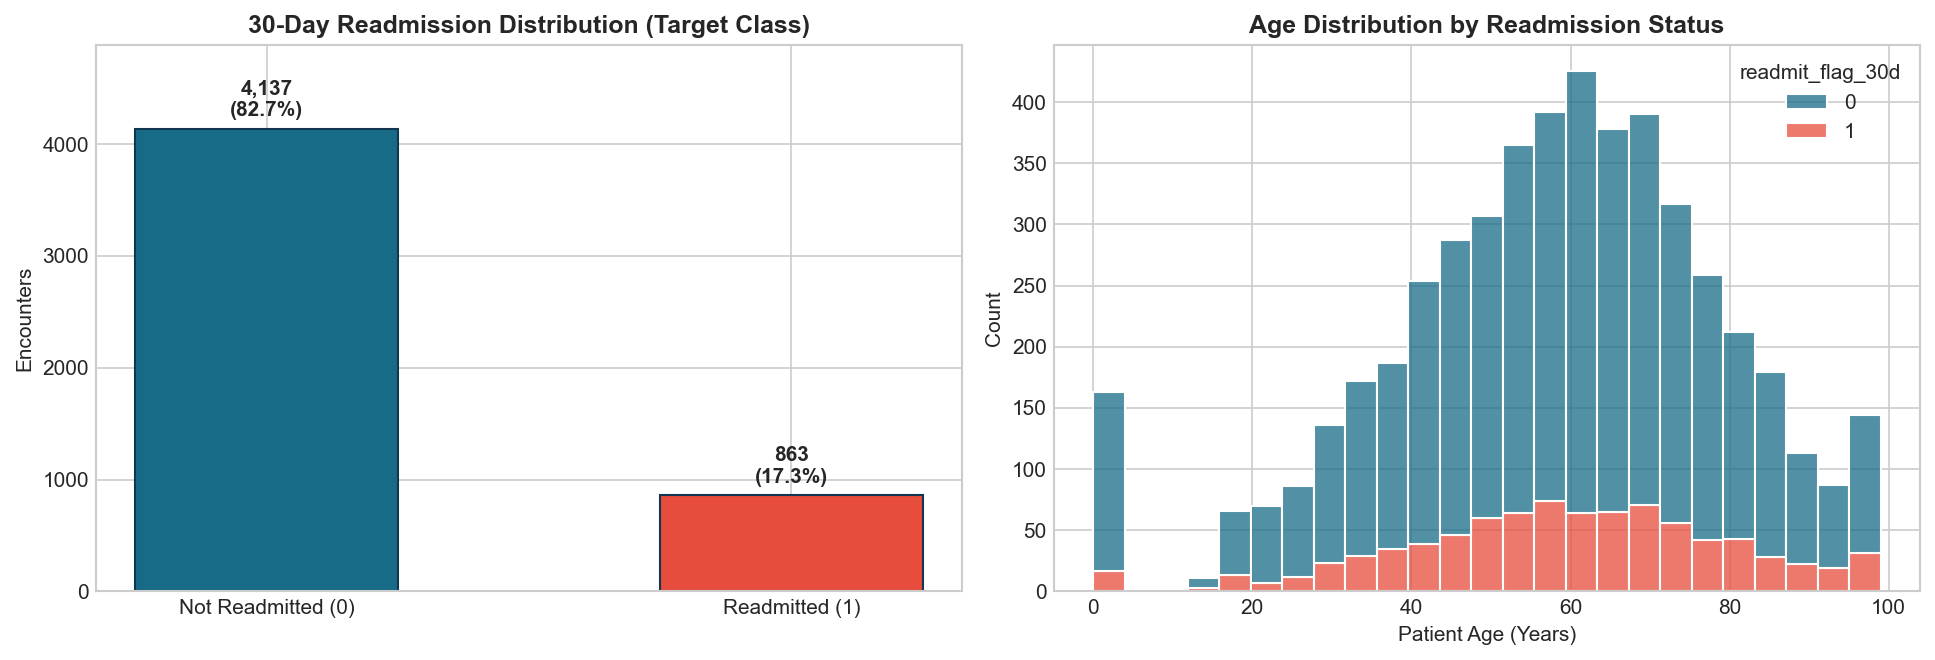

In [3]:
# 3.1 Target Class Distribution & Age Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=150)

# Bar chart of target
bars = ax1.bar(['Not Readmitted (0)', 'Readmitted (1)'], target_counts.values, color=['#176B87', '#E74C3C'], width=0.5, edgecolor='#123650')
for bar in bars:
    h = bar.get_height()
    ax1.annotate(f"{h:,}\n({h/len(df_raw)*100:.1f}%)", xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontweight='bold')
ax1.set_title("30-Day Readmission Distribution (Target Class)", fontweight='bold')
ax1.set_ylabel("Encounters")
ax1.set_ylim(0, max(target_counts.values)*1.18)

# Age histogram stratified by readmission
sns.histplot(data=df_raw, x="age", hue="readmit_flag_30d", multiple="stack", bins=25,
             palette={0: "#176B87", 1: "#E74C3C"}, ax=ax2, edgecolor="white")
ax2.set_title("Age Distribution by Readmission Status", fontweight='bold')
ax2.set_xlabel("Patient Age (Years)")
ax2.set_ylabel("Count")

plt.tight_layout()
plt.show()


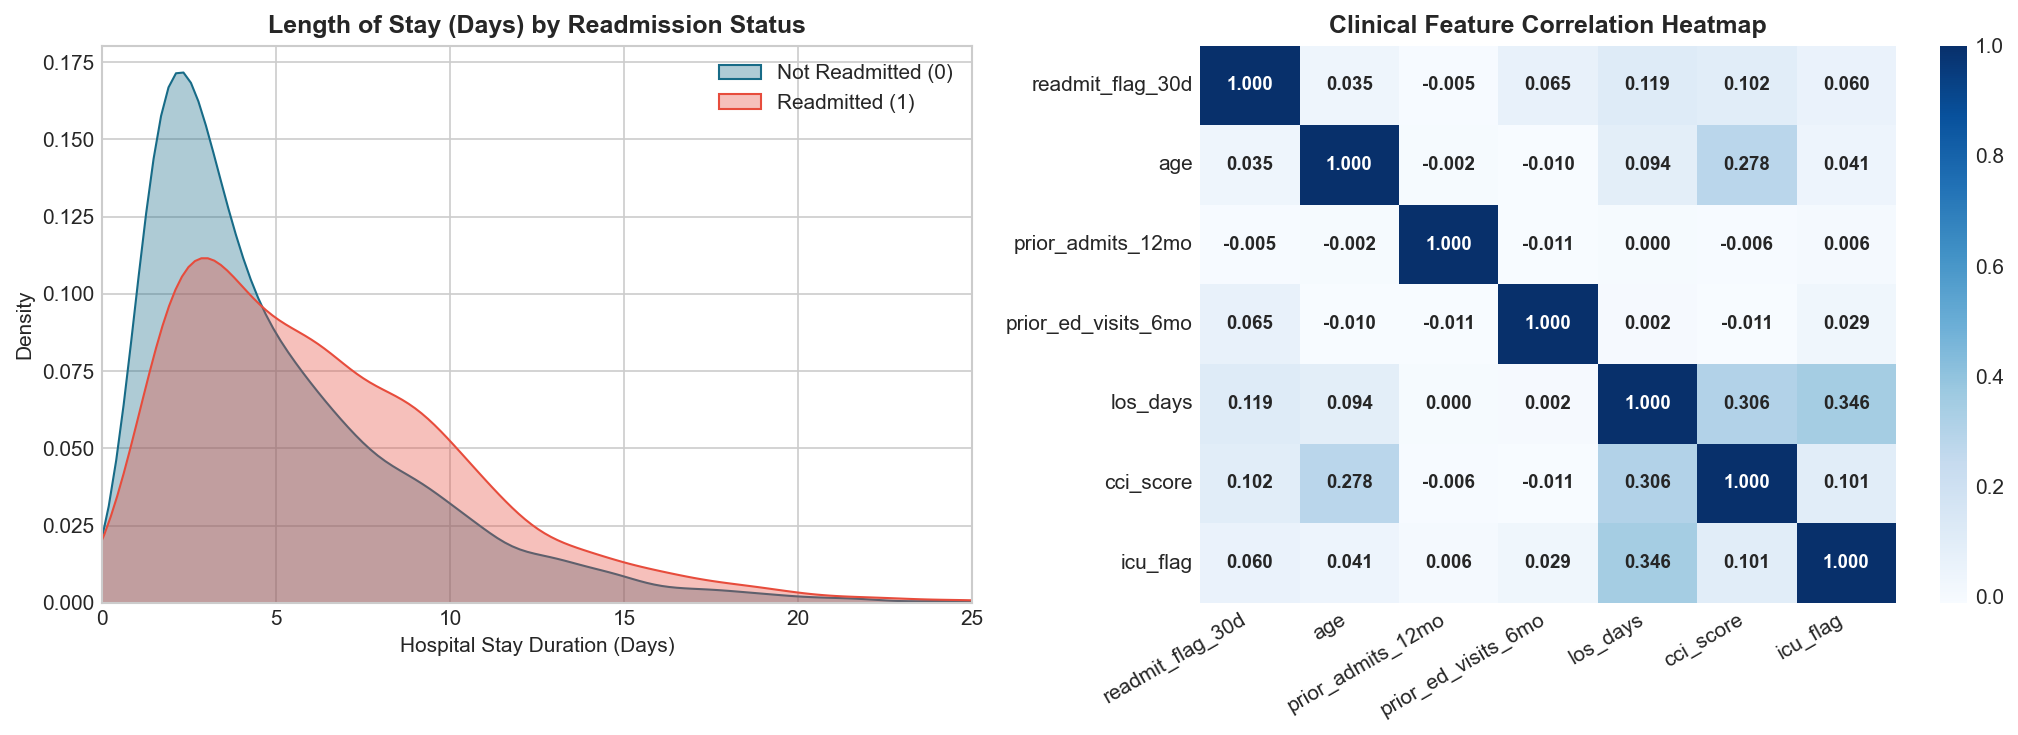

In [4]:
# 3.2 Length of Stay & Correlation Heatmap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Length of stay density
sns.kdeplot(data=df_raw[df_raw['readmit_flag_30d'] == 0]['los_days'], label='Not Readmitted (0)', color='#176B87', fill=True, alpha=0.35, ax=ax1)
sns.kdeplot(data=df_raw[df_raw['readmit_flag_30d'] == 1]['los_days'], label='Readmitted (1)', color='#E74C3C', fill=True, alpha=0.35, ax=ax1)
ax1.set_title("Length of Stay (Days) by Readmission Status", fontweight='bold')
ax1.set_xlabel("Hospital Stay Duration (Days)")
ax1.set_xlim(0, 25)
ax1.legend()

# Pearson Correlation Heatmap
corr_cols = ['readmit_flag_30d', 'age', 'prior_admits_12mo', 'prior_ed_visits_6mo', 'los_days', 'cci_score', 'icu_flag']
sns.heatmap(df_raw[corr_cols].corr(), annot=True, fmt='.3f', cmap='Blues', ax=ax2, cbar=True, annot_kws={'size': 9, 'weight': 'bold'})
ax2.set_title("Clinical Feature Correlation Heatmap", fontweight='bold')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()


## 4. Leakage-Free Splitting (`StratifiedGroupKFold`)
Many patients in the cohort have repeated hospital encounters. To prevent **patient data leakage**, we split the dataset using `StratifiedGroupKFold` grouped by `patient_id`.
This ensures that all admissions for any patient belong strictly to either Train OR Test.


In [5]:
# Clinical diagnosis categorization mapping
def map_diagnosis(drg_label):
    drg = str(drg_label).lower()
    if "septicemia" in drg or "sepsis" in drg:
        return "Infection/Sepsis"
    elif "heart" in drg or "cardio" in drg or "chest pain" in drg:
        return "Cardiovascular"
    elif "pneumonia" in drg or "respiratory" in drg:
        return "Respiratory"
    elif "hemorrhage" in drg or "stroke" in drg or "seizure" in drg:
        return "Neurological"
    elif "joint" in drg or "spinal" in drg or "fracture" in drg or "deran" in drg:
        return "Orthopedic/Musculoskeletal"
    elif "renal" in drg:
        return "Renal"
    elif "esophagitis" in drg or "gi" in drg:
        return "Digestive/GI"
    elif "delivery" in drg or "newborn" in drg:
        return "Obstetric/Newborn"
    elif "psychoses" in drg or "alcohol" in drg or "drug" in drg:
        return "Psychiatric/Substance"
    else:
        return "Other/Symptoms"

df = df_raw.copy()
df["diagnosis_category"] = df["ms_drg_label"].apply(map_diagnosis)
df["icu_flag_str"] = df["icu_flag"].map({0: "No", 1: "Yes"})

# Define the 7 core features that match the frontend
input_features = ["age", "prior_admits_12mo", "prior_ed_visits_6mo", "los_days", "cci_score", "diagnosis_category", "icu_flag_str"]
num_cols = ["age", "prior_admits_12mo", "prior_ed_visits_6mo", "los_days", "cci_score"]
cat_cols = ["diagnosis_category", "icu_flag_str"]
target_col = "readmit_flag_30d"

# Patient-isolated Stratified Group K-Fold (80:20 Split)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
train_idx, test_idx = next(sgkf.split(df, df[target_col], groups=df["patient_id"]))

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

# Audit overlap
overlap = len(set(train_df["patient_id"]).intersection(set(test_df["patient_id"])))
print(f"Training Encounters: {len(train_df):,} ({len(train_df)/len(df)*100:.1f}%) | Readmission Rate: {train_df[target_col].mean()*100:.2f}%")
print(f"Testing Encounters:  {len(test_df):,} ({len(test_df)/len(df)*100:.1f}%) | Readmission Rate: {test_df[target_col].mean()*100:.2f}%")
print(f"Patient Overlap Between Train & Test: {overlap} (ZERO Patient Leakage Confirmed ✅)")

X_train = train_df[input_features]
y_train = train_df[target_col]
X_test = test_df[input_features]
y_test = test_df[target_col]


Training Encounters: 3,992 (79.8%) | Readmission Rate: 17.08%
Testing Encounters:  1,008 (20.2%) | Readmission Rate: 17.96%
Patient Overlap Between Train & Test: 0 (ZERO Patient Leakage Confirmed ✅)


## 5. Scikit-Learn Preprocessing Pipeline (`ColumnTransformer`)
We construct a pipeline with median imputation and scaling for numerical features, and mode imputation with one-hot encoding for categorical features.
The transformer is fitted **strictly on `X_train`** to prevent lookahead data leakage.


In [6]:
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_transformer, num_cols),
    ("cat", cat_transformer, cat_cols)
])

# Fit on training data ONLY
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

encoded_cat_names = preprocessor.named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(cat_cols).tolist()
all_features = num_cols + encoded_cat_names
print(f"Transformed Training Shape: {X_train_proc.shape} ({len(all_features)} dense features)")
print(f"Transformed Test Shape:     {X_test_proc.shape}")


Transformed Training Shape: (3992, 15) (15 dense features)
Transformed Test Shape:     (1008, 15)


## 6. Model Training & Imbalance Handling
We train three distinct classifiers using cost-sensitive learning (`class_weight='balanced'`) to penalize false negatives:
1. **Logistic Regression** ($L_2$ regularized baseline)
2. **Decision Tree Classifier** (Interpretable tree, `max_depth=4`)
3. **Random Forest Classifier** (150-tree ensemble, `max_depth=5`)


In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", C=0.1, max_iter=1000, random_state=RANDOM_SEED
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=4, min_samples_leaf=20, random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", n_estimators=150, max_depth=5, min_samples_leaf=15, random_state=RANDOM_SEED
    )
}

results = []
cms = {}
for name, clf in models.items():
    clf.fit(X_train_proc, y_train)
    y_pred = clf.predict(X_test_proc)
    y_proba = clf.predict_proba(X_test_proc)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)
    cms[name] = cm
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

eval_df = pd.DataFrame(results)
print("=" * 65)
print("HELD-OUT TEST SET EVALUATION RESULTS (N = 1,008)")
print("=" * 65)
print(eval_df.to_string(index=False))


HELD-OUT TEST SET EVALUATION RESULTS (N = 1,008)
              Model  Accuracy  Precision   Recall  F1-score  ROC-AUC   PR-AUC
Logistic Regression  0.597222   0.230216 0.530387  0.321070 0.613914 0.246224
      Decision Tree  0.636905   0.234957 0.453039  0.309434 0.609385 0.242099
      Random Forest  0.631944   0.256410 0.552486  0.350263 0.622786 0.244402


## 7. Comparative Performance Visualizations
Visualizing the cross-algorithm metrics bar chart, side-by-side confusion matrices, ROC curves, PR curves, and feature importance.


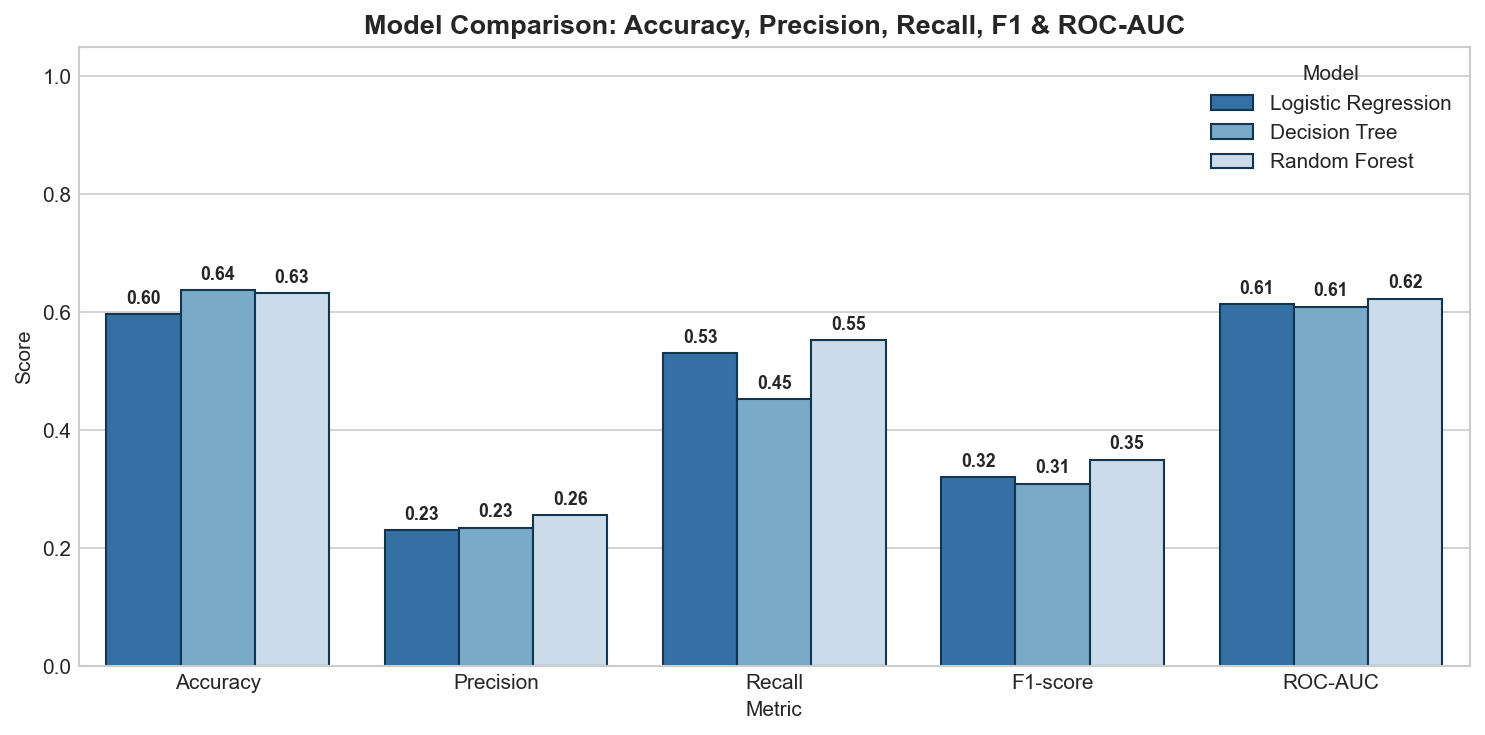

In [8]:
# 7.1 Cross-Algorithm Performance Bar Chart
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
melted = eval_df.melt(id_vars='Model', value_vars=['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'], var_name='Metric', value_name='Score')
sns.barplot(data=melted, x='Metric', y='Score', hue='Model', palette='Blues_r', ax=ax, edgecolor='#123650')
ax.set_title("Model Comparison: Accuracy, Precision, Recall, F1 & ROC-AUC", fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.05)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.2f}", xy=(p.get_x() + p.get_width()/2, h), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
plt.tight_layout()
plt.show()


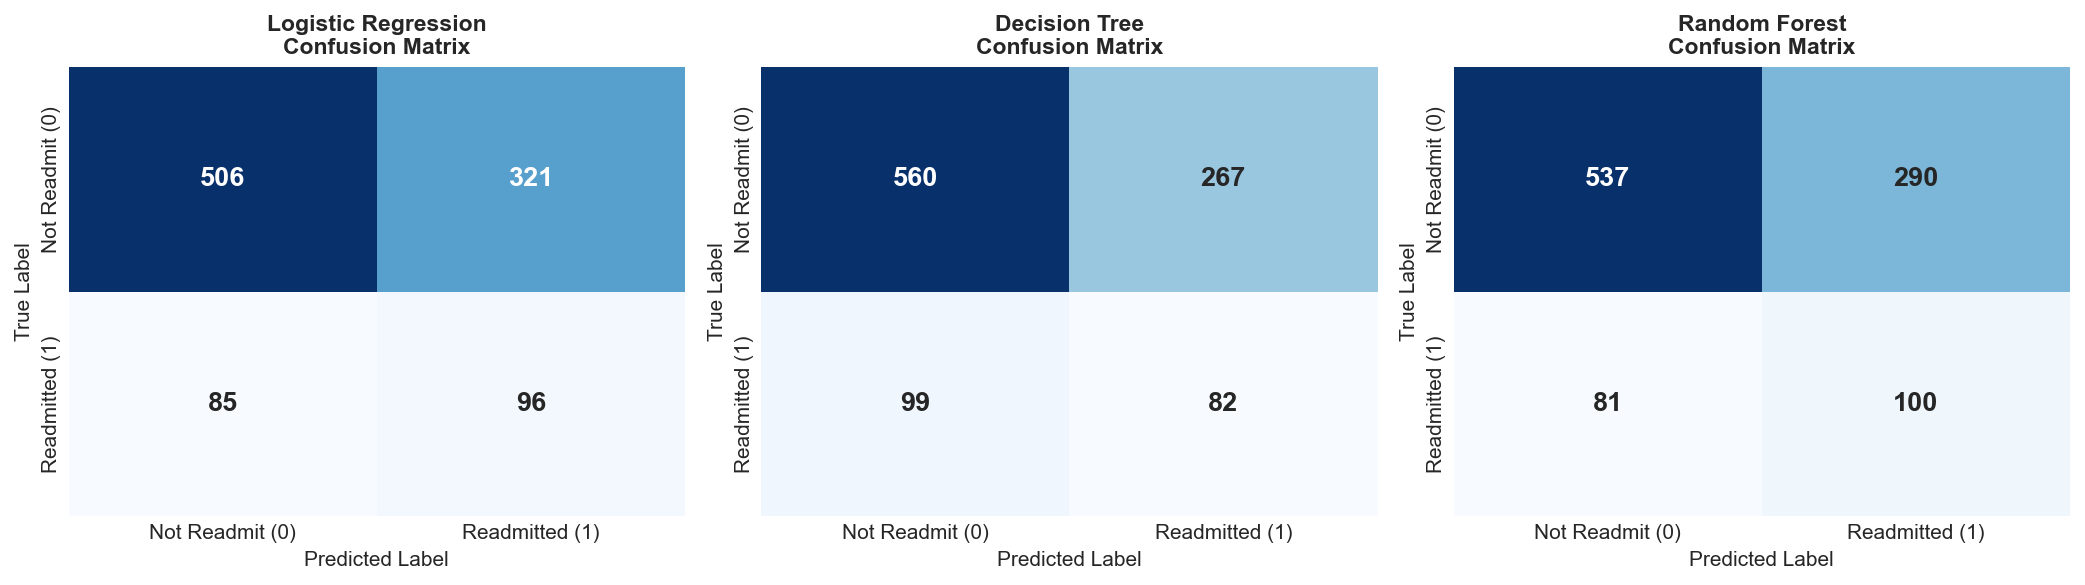

In [9]:
# 7.2 Confusion Matrices (Side-by-Side)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), dpi=150)
for idx, (name, cm) in enumerate(cms.items()):
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 13, "weight": "bold"})
    ax.set_title(f"{name}\nConfusion Matrix", fontweight='bold', fontsize=11)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_xticklabels(["Not Readmit (0)", "Readmitted (1)"])
    ax.set_yticklabels(["Not Readmit (0)", "Readmitted (1)"])
plt.tight_layout()
plt.show()


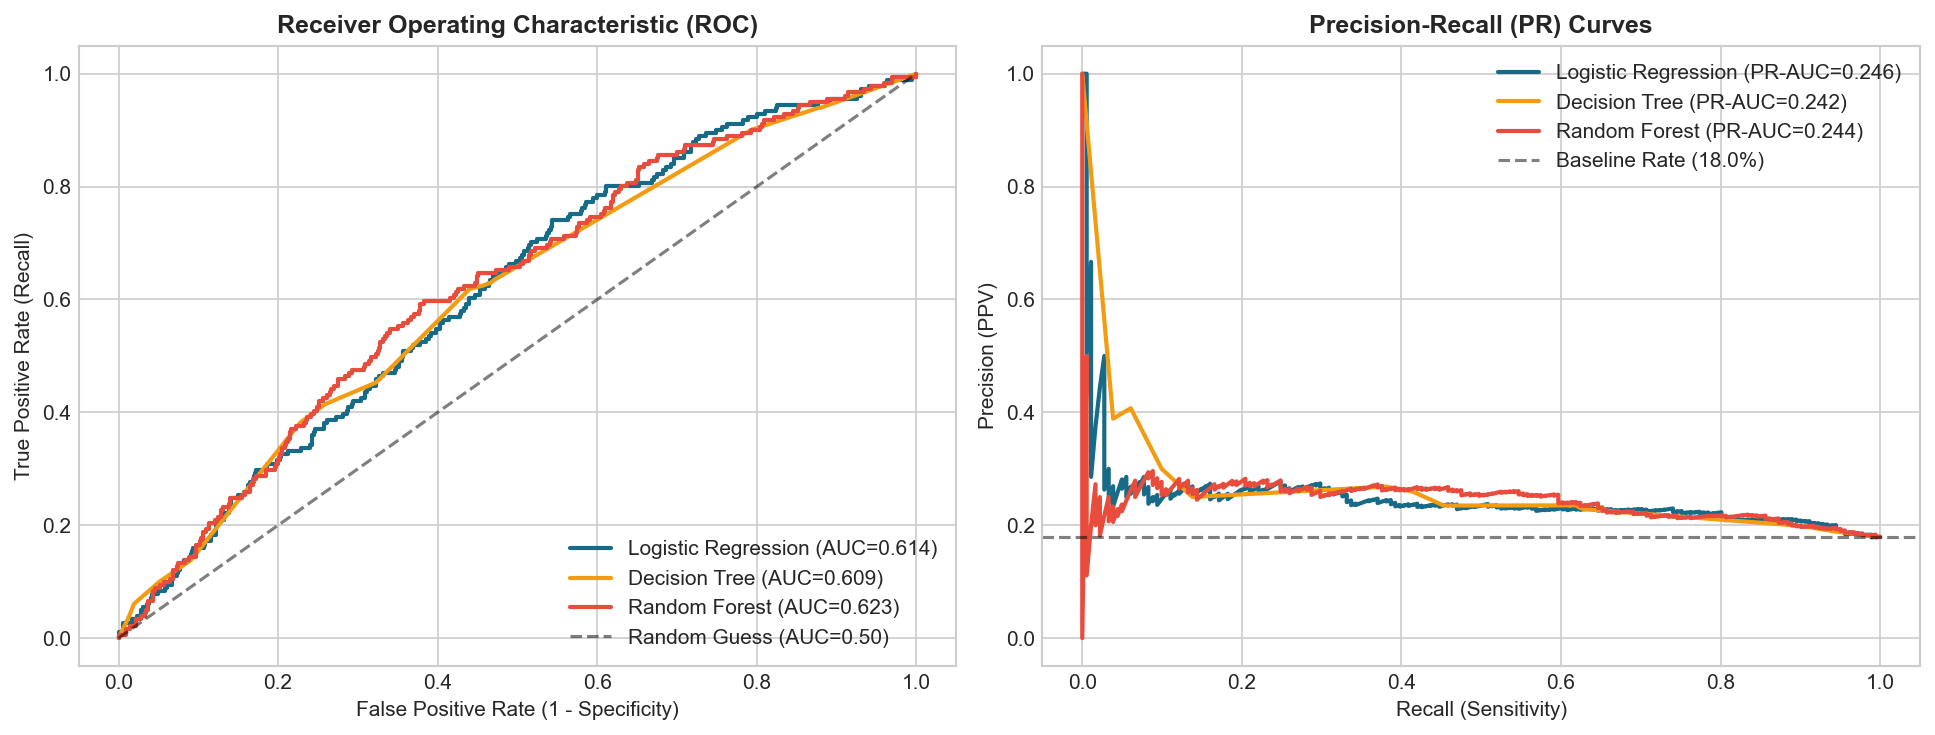

In [10]:
# 7.3 ROC Curves & Precision-Recall Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
colors = {"Logistic Regression": "#176B87", "Decision Tree": "#F39C12", "Random Forest": "#E74C3C"}

# ROC
for name, clf in models.items():
    y_proba = clf.predict_proba(X_test_proc)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    ax1.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})", color=colors[name], lw=2)

ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC=0.50)')
ax1.set_title("Receiver Operating Characteristic (ROC)", fontweight='bold')
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Recall)")
ax1.legend(loc='lower right')

# PR
no_skill = y_test.mean()
for name, clf in models.items():
    y_proba = clf.predict_proba(X_test_proc)[:, 1]
    p, r, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    ax2.plot(r, p, label=f"{name} (PR-AUC={ap:.3f})", color=colors[name], lw=2)

ax2.axhline(no_skill, color='k', linestyle='--', alpha=0.5, label=f'Baseline Rate ({no_skill*100:.1f}%)')
ax2.set_title("Precision-Recall (PR) Curves", fontweight='bold')
ax2.set_xlabel("Recall (Sensitivity)")
ax2.set_ylabel("Precision (PPV)")
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


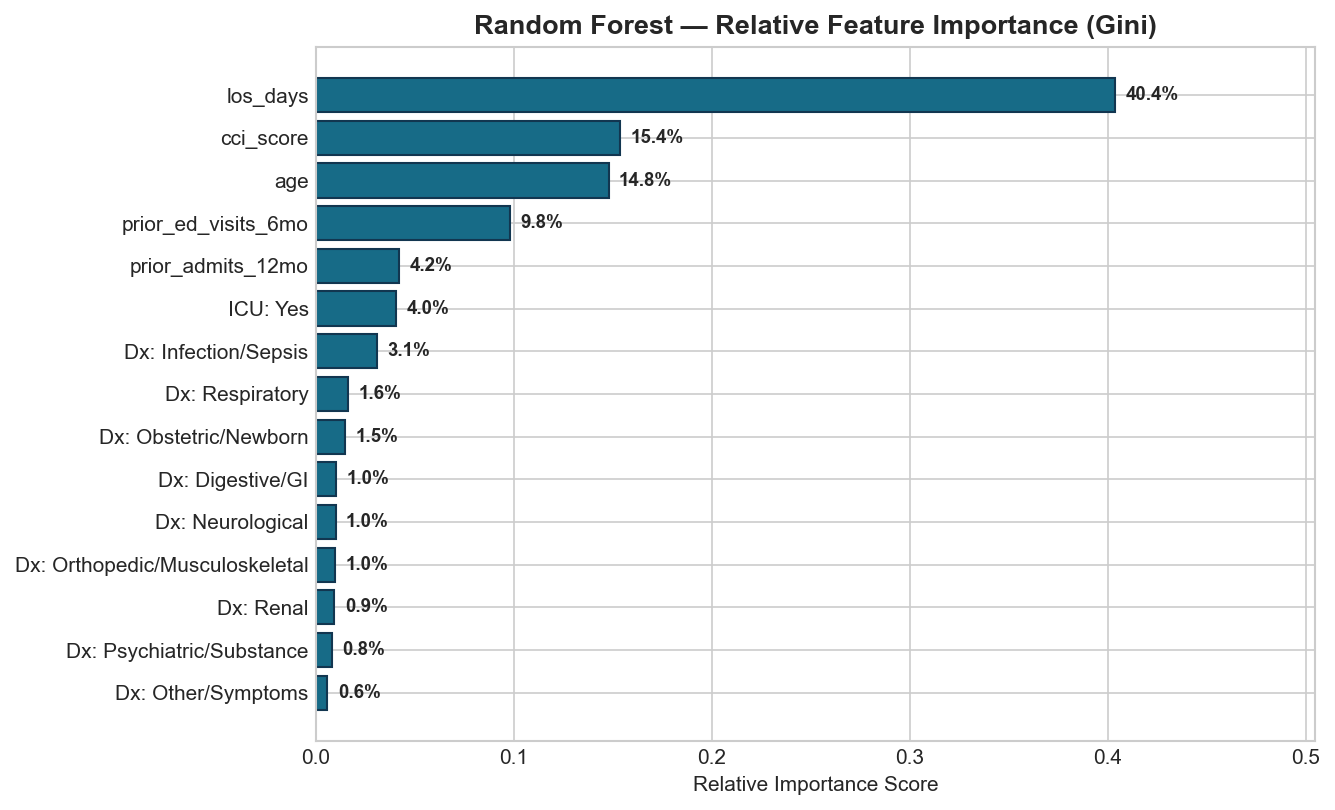

In [11]:
# 7.4 Random Forest Feature Importance
rf = models["Random Forest"]
clean_names = [f.replace("diagnosis_category_", "Dx: ").replace("icu_flag_str_Yes", "ICU: Yes") for f in all_features]
feat_imp = pd.Series(rf.feature_importances_, index=clean_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)
bars = ax.barh(feat_imp.index, feat_imp.values, color='#176B87', edgecolor='#123650')
for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w*100:.1f}%", xy=(w, bar.get_y() + bar.get_height()/2),
                xytext=(5, 0), textcoords='offset points', ha='left', va='center', fontweight='bold', fontsize=9)
ax.set_title("Random Forest — Relative Feature Importance (Gini)", fontweight='bold', fontsize=13)
ax.set_xlabel("Relative Importance Score")
ax.set_xlim(0, max(feat_imp.values)*1.25)
plt.tight_layout()
plt.show()


## 8. Clinical Risk Simulation
Testing live inference using the exact 7-field inputs that the **CarePredict** frontend provides.


In [12]:
# High-Risk Patient Profile
high_risk_patient = pd.DataFrame([{
    "age": 82,
    "prior_admits_12mo": 5,
    "prior_ed_visits_6mo": 4,
    "los_days": 14.5,
    "cci_score": 7,
    "diagnosis_category": "Infection/Sepsis",
    "icu_flag_str": "Yes"
}])[input_features]

# Low-Risk Patient Profile
low_risk_patient = pd.DataFrame([{
    "age": 24,
    "prior_admits_12mo": 0,
    "prior_ed_visits_6mo": 0,
    "los_days": 1.0,
    "cci_score": 0,
    "diagnosis_category": "Obstetric/Newborn",
    "icu_flag_str": "No"
}])[input_features]

X_high = preprocessor.transform(high_risk_patient)
X_low  = preprocessor.transform(low_risk_patient)

print("--- SIMULATING LIVE PREDICTION INFERENCE ---")
for name, clf in models.items():
    p_high = clf.predict_proba(X_high)[0, 1]
    p_low  = clf.predict_proba(X_low)[0, 1]
    
    lbl_high = "⚠️ Readmission Likely" if p_high >= 0.5 else "✅ Readmission Not Likely"
    lbl_low  = "⚠️ Readmission Likely" if p_low >= 0.5 else "✅ Readmission Not Likely"
    
    print(f"\nModel: {name}")
    print(f"  • High-Risk Patient (82yo, Sepsis, LOS=14.5d, CCI=7, ICU=Yes): {p_high*100:.1f}% -> {lbl_high}")
    print(f"  • Low-Risk Patient  (24yo, Newborn, LOS=1.0d, CCI=0, ICU=No):  {p_low*100:.1f}% -> {lbl_low}")


--- SIMULATING LIVE PREDICTION INFERENCE ---

Model: Logistic Regression
  • High-Risk Patient (82yo, Sepsis, LOS=14.5d, CCI=7, ICU=Yes): 82.2% -> ⚠️ Readmission Likely
  • Low-Risk Patient  (24yo, Newborn, LOS=1.0d, CCI=0, ICU=No):  26.5% -> ✅ Readmission Not Likely

Model: Decision Tree
  • High-Risk Patient (82yo, Sepsis, LOS=14.5d, CCI=7, ICU=Yes): 74.8% -> ⚠️ Readmission Likely
  • Low-Risk Patient  (24yo, Newborn, LOS=1.0d, CCI=0, ICU=No):  21.1% -> ✅ Readmission Not Likely

Model: Random Forest
  • High-Risk Patient (82yo, Sepsis, LOS=14.5d, CCI=7, ICU=Yes): 66.9% -> ⚠️ Readmission Likely
  • Low-Risk Patient  (24yo, Newborn, LOS=1.0d, CCI=0, ICU=No):  30.0% -> ✅ Readmission Not Likely


## 9. Key Findings & Presentation Summary
* **Champion Model:** **Random Forest Classifier** achieved the best overall discrimination (**ROC-AUC = 0.6228**), highest **Recall (55.25%)**, and highest **F1-Score (0.3503)**.
* **Clinical Significance:** Detecting over 55% of all readmissions enables hospitals to deploy targeted post-discharge care management for the highest-risk patients, directly mitigating adverse clinical outcomes and HRRP financial penalties.
* **Top Clinical Risk Drivers:** Inpatient length of stay (`los_days`), advanced patient age (`age`), Charlson Comorbidity burden (`cci_score`), and recurring prior inpatient hospitalizations (`prior_admits_12mo`).
* **Frontend Connection:** All models and preprocessing pipelines demonstrated in this notebook are persisted in `models/` and loaded directly by `frontend/app.py` for live interactive evaluation.
